# 05 — Chunking definitivo da jurisprudência

Aplicação da decisão do notebook 04 à base limpa, protegida e consolidada pelo notebook 03: **janela fixa de 500 tokens, com sobreposição-alvo de 100 tokens (20%)**, usando o tokenizador do BGE-M3 no snapshot dos experimentos. Não há classificação de seção ou tema.

“Definitivo” identifica a configuração escolhida, não garante que uma execução parcial já represente toda a base. As células mostram o andamento real e distinguem lotes concluídos de corpus integral validado. Os experimentos e os notebooks anteriores permanecem preservados.

Esta etapa gera chunks e metadados; embeddings e armazenamento no pgvector pertencem à etapa seguinte.

## 1. Importação de bibliotecas e configuração

Leitura local dos relatórios e uso do tokenizador BGE-M3 já disponível. Não há chamada a LLM, download de modelo ou geração de vetores. A execução é incremental, com esquema Parquet fixo e um checkpoint por lote de até 128 registros de entrada.

In [1]:
from pathlib import Path
import sys,json,subprocess
import pandas as pd
from IPython.display import display,Markdown
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/jurisprudencia').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.jurisprudencia import chunking_definitivo as pipeline
from src.jurisprudencia import chunking_definitivo_relatorio as painel
print('Estratégia:',pipeline.NAME)
print('Tokenizador:',pipeline.piloto_bge.MODEL)
print('Revisão:',pipeline.piloto_bge.REVISION)

Estratégia: fixa_500_o100
Tokenizador: BAAI/bge-m3
Revisão: 5617a9f61b028005a4858fdac845db406aefb181


## 2. Importação da base tratada e definição do recorte

A entrada é a versão pós-PLN do notebook 03, com 179.812 registros da base reduzida. O recorte usa **`candidato_consolidado`**, sem nova triagem por perguntas ou resultados: 169.821 documentos, aproximadamente 3,9 bilhões de caracteres. Os candidatos de TRT/TST e STF foram definidos pelas regras automáticas já registradas.

Lê-se o campo principal indicado em cada registro, mantendo a distinção entre ementa e inteiro teor. Os originais e o CSV tratado não são regravados. A contagem dos candidatos não é uma garantia de integralidade jurídica ou representatividade da jurisprudência.

In [2]:
ESTADO_CHUNKING=painel.show_scope(ROOT)

Versão do tokenizador: 5617a9f61b028005a4858fdac845db406aefb181
Hash da configuração: 9d3c9928aeb46c6650379a64a708b2b9ddfb563af7cd4ac328e22dfee24b72a1


,registros_entrada,documentos_elegiveis,fora_do_recorte,caracteres_elegiveis,tokens_por_janela,sobreposicao_alvo
0,179812,169821,9991,3906308921,500,100


,arquivo_id,documentos_elegiveis,caracteres
0,f01,11952,23784882
1,f03,1809,21636535
2,f04,2404,46221928
3,f06,2713,30195871
4,f07,325,7116714
5,f08,13770,344427285
6,f09,867,19244671
7,f10,12105,301682460
8,f11,1,10265
9,f12,16194,354496121


**Texto usado:** campo principal protegido indicado no notebook 03, sem concatenar ementa e inteiro teor. As exclusões do recorte são lógicas: os registros de origem continuam preservados.

## 3. Geração dos chunks — execução por lotes e retomada

O processamento integral foi iniciado pelo executor abaixo, fora do kernel de leitura deste notebook, para não bloquear suas células de análise. Cada lote só recebe checkpoint após fechar os Parquets e calcular seus hashes. A retomada verifica os lotes existentes e continua sem duplicá-los; um bloqueio impede dois escritores na mesma versão.

Para iniciar ou retomar após a execução anterior terminar ou ser interrompida, execute no terminal da raiz do projeto:

```powershell
.venv\Scripts\python.exe -u scripts/run_chunking_definitivo_jurisprudencia.py
```

Sem `--max-lotes`, o executor percorre todo o recorte e faz a auditoria global ao final. A opção `--max-lotes N` é apenas uma parada controlada para verificação técnica. Ela não transforma o lote em corpus completo.

O parâmetro abaixo fica desativado para que “Executar tudo” não abra um segundo processamento enquanto o executor já trabalha. As demais células leem os resultados existentes e podem ser atualizadas durante a execução.

In [3]:
EXECUTAR_PROCESSAMENTO=False
MAX_LOTES=None
if EXECUTAR_PROCESSAMENTO:
    estado_execucao,progresso_execucao=pipeline.run(ROOT,max_lotes=MAX_LOTES)
    if progresso_execucao['documentos_restantes']==0:pipeline.finalize(estado_execucao)
ESTADO_CHUNKING=painel.show_progress(ROOT)

Relatórios: reports\jurisprudencia\chunking_definitivo\9d3c9928aeb46c6650379a64a708b2b9ddfb563af7cd4ac328e22dfee24b72a1
Parquets: data\chunks\jurisprudencia\definitivo\9d3c9928aeb46c6650379a64a708b2b9ddfb563af7cd4ac328e22dfee24b72a1


,status,documentos_esperados,documentos_processados,documentos_restantes,chunks,lotes_concluidos,atualizado_em_utc
0,chunking_validado,169821,169821,0,2568877,1337,2026-11-16T12:41:13.898570+00:00


**Estado:** corpus completo e validado; consulte o manifesto final.

## 4. Estrutura dos chunks e vínculos com os documentos

Cada chunk recebe ID estável, hash próprio, hash do documento-base, campo de origem, ordem e intervalos de caracteres `[inicio, fim)`. Preservam-se tribunal, processo, datas distintas, classe, proveniência, grupo de avaliação e split proposto. `parent_arquivo` e seu SHA-256 apontam para o Parquet protegido que contém o documento completo.

As unidades respeitam até 500 tokens de texto, além dos dois tokens especiais do encoder. A sobreposição é alvo de 100 tokens: a retokenização nas bordas e a preservação do marcador de CPF podem produzir pequenas diferenças no valor observado. Não se cortam nem removem silenciosamente o final do documento ou marcadores de proteção.

In [4]:
painel.show_schema(ROOT)

Texto, relator e número de processo não são exibidos no painel de amostra.


,campo,tipo
0,chunk_id,string
1,registro_id,string
2,arquivo_id,string
3,tribunal,string
4,campo_texto,string
5,tipo_conteudo_declarado,string
6,tipo_conteudo_inferido,string
7,ordem,int64
8,inicio,int64
9,fim,int64


,campo_texto,ordem,inicio,fim,tokens,sobreposicao_anterior_tokens,split_proposto,chunk_id_prefixo,registro_id_prefixo
0,ementa,0,0,1054,293,0,validacao,fd21a0e0d7ae,5b58a7c344f3
1,ementa,0,0,1963,500,0,treino,601bb22a673a,7101ea0b3a92
2,ementa,1,1517,2578,231,100,treino,bce0c8db256e,7101ea0b3a92
3,ementa,0,0,536,144,0,treino,23726bfc98bc,12b1c27cae86
4,ementa,0,0,1912,500,0,treino,c26b5725cf8a,e13ec8fc5077


## 5. Testes de integridade, reconstrução e preservação das partições

Durante a geração, cada documento é reconstruído pela união dos intervalos, descontando a sobreposição, e confrontado com o texto de entrada. São verificados limites, hashes, IDs e marcadores de CPF. Abaixo há releitura de lotes já fechados e testes automatizados; isso não substitui a auditoria global de todo o recorte.

Ao concluir, o executor relê todos os lotes, reconstrói os hashes documentais, confere a unicidade dos IDs em SQLite e verifica grupos e splits. Cópias textuais são contabilizadas sem apagar seus vínculos de origem. Só depois são emitidos `manifesto_lotes.json` e `concluido.json`.

In [5]:
display(painel.verify_samples(ROOT,limit=3))
TESTES_CHUNKING_DEFINITIVO=subprocess.run([sys.executable,'-m','unittest','discover','-s',str(ROOT/'tests'),
    '-p','test_chunking_definitivo.py'],cwd=ROOT,capture_output=True,text=True)
print(TESTES_CHUNKING_DEFINITIVO.stdout+TESTES_CHUNKING_DEFINITIVO.stderr)
assert TESTES_CHUNKING_DEFINITIVO.returncode==0

Documentos elegÃ­veis: 2 | concluÃ­dos: 0
Checkpoint: f01_000000 documentos 2 chunks 2 segundos 0.0
Documentos elegÃ­veis: 2 | concluÃ­dos: 2
Documentos elegÃ­veis: 2 | concluÃ­dos: 2
........
----------------------------------------------------------------------
Ran 8 tests in 0.293s

OK



,lote,documentos,chunks,reconstrucao,sha256
0,lote_f01_000000,128,209,aprovada,conferido
1,lote_f01_000001,128,217,aprovada,conferido
2,lote_f20_000186,67,1316,aprovada,conferido


## 6. Análise e avaliação dos resultados — andamento por arquivo

Os gráficos mostram documentos e chunks efetivamente gravados em lotes fechados. A base contém fontes de tamanhos diferentes; os primeiros arquivos não determinam o custo dos próximos. Durante o processamento, essas figuras são fotografias parciais, não resultados finais de toda a base.

Execute novamente esta célula para atualizar a visualização. A distribuição global de tokens e as contagens finais por tribunal e partição são publicadas apenas após a auditoria integral.

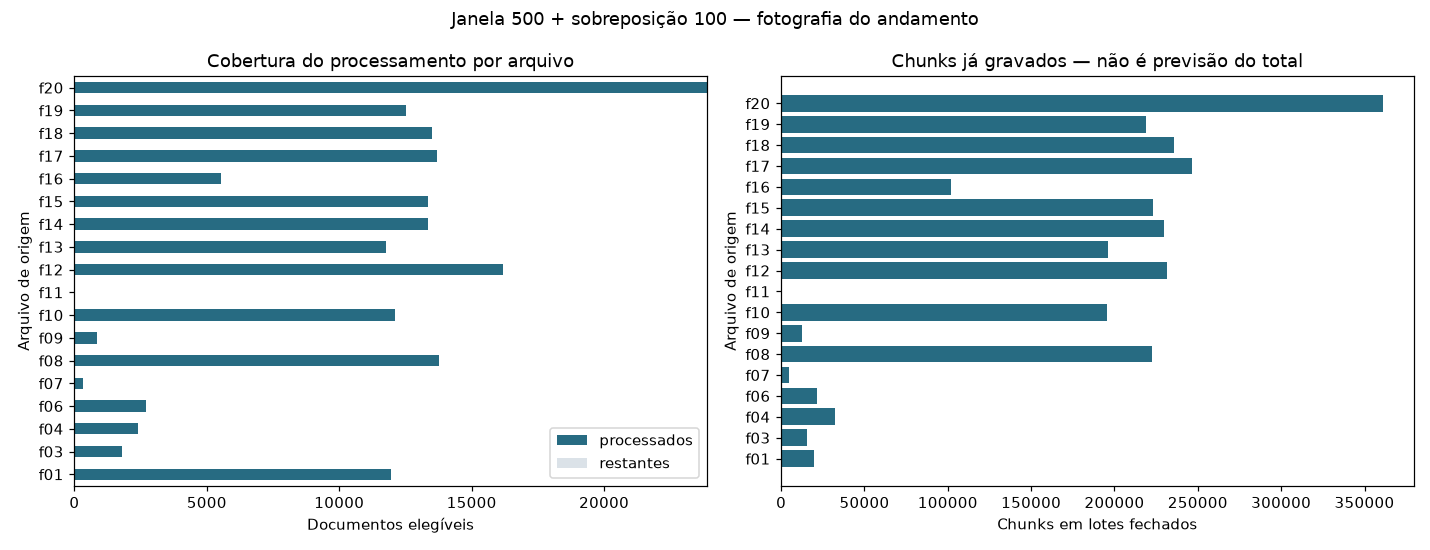

In [6]:
ANDAMENTO_POR_ARQUIVO=painel.show_plots(ROOT)

## 7. SALVANDO O DATASET DE CHUNKS E O MANIFESTO VERSIONADO

O processamento grava Parquet por lote para permitir leitura incremental de milhões de unidades. A identidade da versão fixa fontes, índice de candidatos, regra de chunking, tokenizador, código e a célula de decisão do notebook 04. CSVs agregados facilitam a inspeção das contagens, sem duplicar todo o texto jurídico em uma nova exportação gigante.

As saídas ficam em `data/chunks/jurisprudencia/definitivo/<versão>/`; os relatórios, em `reports/jurisprudencia/chunking_definitivo/<versão>/`. O ponteiro `ativa.json` localiza a execução atual. Um consumidor da próxima etapa deve exigir o estado **`chunking_validado`**, não apenas a presença de arquivos Parquet.

In [7]:
painel.show_outputs(ROOT)

,artefato,conteudo,disponibilidade
0,chunks_*.parquet,"Texto do chunk, tokens, offsets, metadados e v...",por lote concluído
1,documentos_*.parquet,Hash do texto-base e reconciliação por documento,por lote concluído
2,configuracao.json,"Regra, recorte, fontes e versões fixadas",criado
3,lote_*.json,Hashes e contagens que permitem retomada,por lote concluído
4,progresso.json,Fotografia de contagens e estado,atualizado durante execução
5,manifesto_lotes.json,Lista integral dos lotes e respectivos hashes,gerado ao concluir e validar
6,concluido.json,Resultado da auditoria global,gerado ao concluir e validar


,tribunal,documentos
0,TST,100000
1,TRT-17,27068
2,TRT-10,23875
3,TRT-13,11952
4,STF,6926


,split,documentos
0,teste,16894
1,treino,135945
2,validacao,16982


,tokens,chunks
0,55,1
1,58,1
2,60,2
3,61,2
4,62,1
5,63,2
6,65,1
7,67,2
8,68,2
9,70,8


**Formato:** chunks e documentos são gravados em Parquet por lote, para leitura incremental. Os CSVs são tabelas agregadas de auditoria. O CSV limpo do notebook 03 permanece preservado; não se duplica todo o texto em um segundo CSV gigante.

## 8. Diagnóstico e observações — proteção de dados pessoais e integração

O painel abaixo informa o estado observado, os limites da proteção e o ponto de passagem para embeddings. Não se recalculam EDA, limpeza ou testes de estratégias nesta etapa. A presença de um chunk não implica validação da interpretação jurídica do documento nem suficiência para responder a uma pergunta.

In [8]:
painel.show_diagnosis(ROOT)

**Chunking concluído e validado:** 169,821 documentos e 2,568,877 chunks. IDs, hashes, reconstrução, limites e preservação dos grupos/partições passaram na auditoria global.

**Proteção de dados pessoais:** a entrada deriva do mascaramento de CPFs e do PLN conservador. O texto principal é conferido antes de ser dividido, e o marcador `[CPF_REMOVIDO]` não é cortado. Isso não equivale a anonimização integral: nomes e outros dados pessoais podem permanecer nos documentos e metadados.

**Repetições e partições:** não se elimina um chunk apenas porque seu texto coincide com outro; preservam-se documento e proveniência. A auditoria final conta IDs repetidos e cópias textuais separadamente, verifica os grupos de avaliação e mantém os splits propostos pelo notebook 03. Esses splits não são treinamento de modelo.

**Integração seguinte:** somente após `concluido.json` indicar `chunking_validado`, preparar embeddings BGE-M3 com configuração compatível com legislação e importar a coleção própria de jurisprudência no pgvector. Não houve geração de embeddings, criação de banco vetorial ou nova avaliação de respostas nesta etapa.